In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms

from torch.utils.data import Dataset, DataLoader

from transformers import CLIPTokenizer, CLIPTextModel

import os

from tqdm.auto import tqdm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Checking device

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Colab Setup

In [4]:
# ===== Get the latest repo on Colab, then list the dataset folder =====
# Clone if the repo isn't on this server yet; otherwise pull the newest files.
import os
REPO = "/content/generative-models-lab"

if os.path.isdir(REPO):
    !git -C {REPO} pull
else:
    !git clone https://github.com/Divyanshu1331/generative-models-lab.git {REPO}

!ls {REPO}/07-clip/Dataset

Cloning into '/content/generative-models-lab'...
remote: Enumerating objects: 133, done.
remote: Counting objects: 100% (133/133), done.
remote: Compressing objects: 100% (105/105), done.
remote: Total 133 (delta 33), reused 8 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (133/133), 26.05 MiB | 18.16 MiB/s, done.
Resolving deltas: 100% (33/33), done.
ImagePath_caption_colab.csv.gz


In [5]:
# Loding Image-caption pair csv on colab from GitHub

train_data = pd.read_csv("/content/generative-models-lab/07-clip/Dataset/ImagePath_caption_colab.csv.gz")

print(train_data.shape)
train_data.head()

(591753, 2)


,Img_Path,Caption
0,/content/train2017/000000203564.jpg,A bicycle replica with a clock as the front wh...
1,/content/train2017/000000322141.jpg,A room with blue walls and a white sink and door.
2,/content/train2017/000000016977.jpg,A car that seems to be parked illegally behind...
3,/content/train2017/000000106140.jpg,A large passenger airplane flying through the ...
4,/content/train2017/000000106140.jpg,There is a GOL plane taking off in a partly cl...


In [6]:
# Downloading the COCO train images on the COlab's disk
# ============= COCO train2017 images -> /content/train2017 (runs once per Colab session) ===============

import os, zipfile, subprocess, requests

URL      = "http://images.cocodataset.org/zips/train2017.zip"      # URL containing zip file of COCO2017's train images

ZIP_PATH = "/content/train2017.zip"                                # Path on Colab's disk to store COCO's training images in zip file
IMG_DIR  = "/content/train2017"                                    # Path on Colab's disk to store unziped file

EXPECTED = 118287                                                  # number of images in COCO train2017


def count_images():                                                # Count of images in the Colab's image directory

    return len(os.listdir(IMG_DIR)) if os.path.isdir(IMG_DIR) else 0



if count_images() >= EXPECTED:                                     # If images are already extracted, the whole cell is skipped.

    print(f"Already done: {count_images()} images in {IMG_DIR}")

else:

    # Step 0: stop any old background download so two downloads don't fight over one file
    subprocess.run(["pkill", "-x", "wget"])
    subprocess.run(["pkill", "-x", "unzip"])

    # Step 1: download train2017.zip (~18 GB) with a progress bar; resumes if it was cut off
    done = os.path.getsize(ZIP_PATH) if os.path.exists(ZIP_PATH) else 0
    headers = {"Range": f"bytes={done}-"} if done else {}
    with requests.get(URL, stream=True, headers=headers, timeout=60) as r:
        if r.status_code != 416:                       # 416 = file already fully downloaded
            r.raise_for_status()
            if r.status_code != 206:                   # server ignored resume -> start fresh
                done = 0
            total = done + int(r.headers["content-length"])
            with open(ZIP_PATH, "ab" if done else "wb") as f, \
                 tqdm(total=total, initial=done, unit="B", unit_scale=True, desc="Downloading") as bar:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
                    bar.update(len(chunk))

    # Step 2: extract all images with a progress bar
    with zipfile.ZipFile(ZIP_PATH) as zf:
        for member in tqdm(zf.infolist(), desc="Extracting", unit="file"):
            zf.extract(member, "/content")

    # Step 3: delete the zip to free disk space and print the final image count
    os.remove(ZIP_PATH)
    print(f"Done: {count_images()} images in {IMG_DIR}")

Downloading:   0%|          | 0.00/19.3G [00:00<?, ?B/s]

Extracting:   0%|          | 0/118288 [00:00<?, ?file/s]

Done: 118287 images in /content/train2017


In [7]:
# ===== One-time: shrink every image to 224x224 and save as a small JPEG =====
# Decoding full-size COCO images is the data bottleneck on Colab's 2 CPU cores.
# Skips files that already exist, so re-running is safe.

from PIL import Image
from concurrent.futures import ThreadPoolExecutor

SMALL_DIR = "/content/train2017_224"             # Path on Colab's disk where COCO's resized images(224, 224) will be stored

os.makedirs(SMALL_DIR, exist_ok=True)

def shrink(path):
    out = os.path.join(SMALL_DIR, os.path.basename(path))
    if not os.path.exists(out):
        img = Image.open(path)
        img.draft("RGB", (224, 224))                       # fast reduced-size JPEG decode
        img.convert("RGB").resize((224, 224)).save(out, quality=95)

paths = train_data["Img_Path"].unique().tolist()
with ThreadPoolExecutor(4) as ex:
    list(tqdm(ex.map(shrink, paths), total=len(paths), desc="Resizing"))

# Point the dataframe at the small copies
train_data["Img_Path"] = SMALL_DIR + "/" + train_data["Img_Path"].str.split("/").str[-1]

Resizing:   0%|          | 0/118287 [00:00<?, ?it/s]

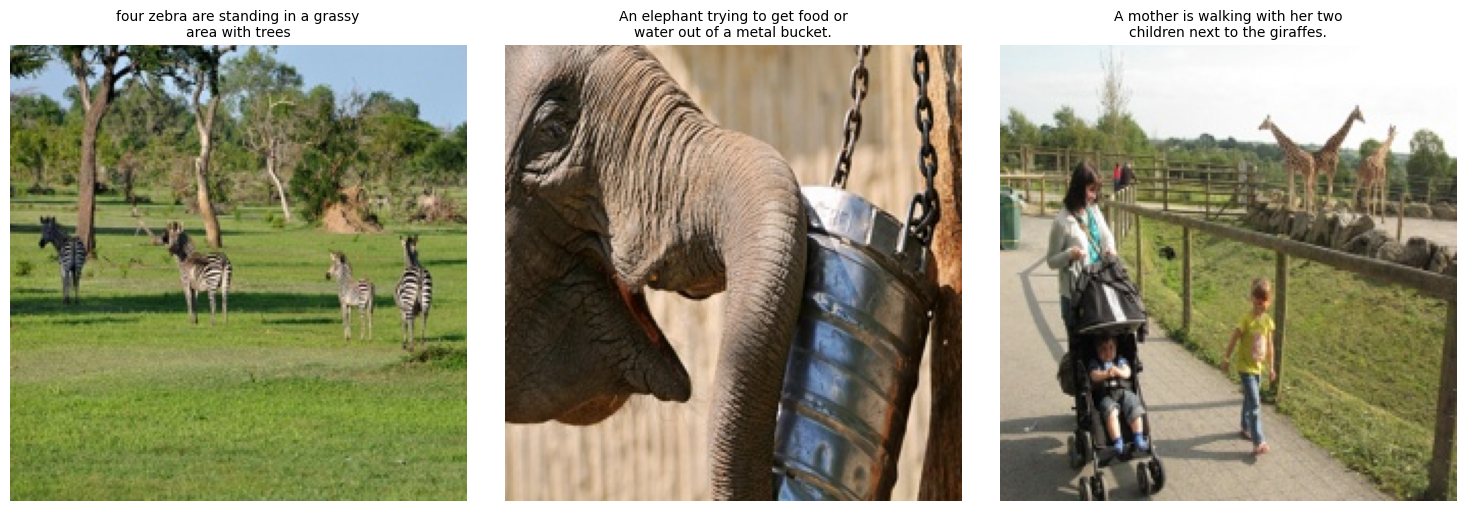

In [8]:
# Viewing Images from the Colab server

import matplotlib.pyplot as plt, textwrap
from PIL import Image

samples = train_data.sample(3)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (_, row) in zip(axes, samples.iterrows()):
    ax.imshow(Image.open(row["Img_Path"]).convert("RGB"))
    ax.set_title("\n".join(textwrap.wrap(row["Caption"], 35)), fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Dataset and DataLoader class

In [9]:
# Creating Dataset Class
# Dataset: one random caption per image per epoch

import random

class coco_dataset(Dataset):
    def __init__(self, data):
        super().__init__()

        groups = data.groupby("Img_Path")["Caption"].apply(list)    # image -> its ~5 captions
        self.paths    = groups.index.tolist()
        self.captions = groups.tolist()
        self.transformation = transforms.ToTensor()

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, index):

        img = Image.open(self.paths[index]).convert("RGB")           # Grayscale images come as 2D [H, W] .convert() automatically makes them 
                                                                     # 3-channel [H, W, 3]
        return self.transformation(img), random.choice(self.captions[index])   # new caption each epoch

In [12]:
# Creating Dataset And DataLoader Object

Batch_Size = 64

train_dataset = coco_dataset(train_data)

train_loader = DataLoader(train_dataset, batch_size = Batch_Size, shuffle = True, drop_last = True, num_workers = 2, pin_memory = True, 
                          persistent_workers = True, prefetch_factor = 4)

# Image Encoder - ViT

In [13]:
# 1 Image Tensor - [16, 3, 224, 224]: We devide (224, 224) image --> into (16, 16) patch. 
# Total no. of patches formed in Image grid: Image size (224x224) / Patch size (16x16) = (14x14),
# And the total number of 16x16 patches = 14x14 = 196.
# We will take the Embedding dimesion = 768.

patch_size = 16
num_patches = 196
emd_dim = 768

In [14]:
# Patch Embedding + Linear Projection + Flattening


class patch_embed(nn.Module):

    def __init__(self):
        super().__init__()
        
        self.conv_patching = nn.Conv2d(in_channels = 3, out_channels = emd_dim, kernel_size = patch_size, stride = patch_size)

    def forward(self, in_tensor):                                           # in_tensor = [16, 3, 224, 224] (Image)
        
        patch_emd = self.conv_patching(in_tensor)                           # [16, 3, 224, 224] --> [16, 768, 14, 14]

        patch_emd = patch_emd.flatten(start_dim = 2, end_dim = 3)           # [16, 768, 14, 14] --> [16, 768, 196]

        patch_emd = patch_emd.permute(0, 2, 1)                              # [16, 768, 196] --> [16, 196, 768]

        return patch_emd                                                    # [16, 196, 768]  (196 vectors of 768-dim of 16 images)


# To be precise, a tensor shape of [16, 196, 768] represents:
# • 16 images in the current batch.
# • 196 is the number of tokens (or patches) per image (14 × 14 = 196).
# • 768 is the size (or dimensionality) of each token.

In [15]:
# Self Attention

class self_attention(nn.Module):

    def __init__(self):
        super().__init__()

        self.q = nn.Linear(emd_dim, emd_dim)
        self.k = nn.Linear(emd_dim, emd_dim)
        self.v = nn.Linear(emd_dim, emd_dim)

        self.softmax = nn.Softmax(dim = -1)

        self.proj = nn.Linear(emd_dim, emd_dim)

    def forward(self, x):                          # x --> Input feature map [16, 197, 768] - 197: 196 + 1 (CLS token)
        
        q = self.q(x)
        k = self.k(x)
        v = self.v(x)

        attn = q @ k.permute(0, 2, 1)             # Q [16, 197, 768] dot K_transpose [16, 768, 197] = [16, 197, 197]
        attn = attn / emd_dim ** 0.5
        attn = self.softmax(attn)                 # Softmax on tokens --> dim = -1; tensor[2] = [197]
        attn = attn @ v                           # [16, 197, 197] dot V [16, 197, 768] = [16, 197, 768]

        attn = self.proj(attn)

        return attn

In [16]:
# Multi-Head attention

class multi_attention(nn.Module):
    def __init__(self, num_heads):
        super().__init__()

        self.head = nn.ModuleList([self_attention() for _ in range(num_heads)])

        self.proj = nn.Linear(emd_dim * num_heads, emd_dim)

    def forward(self, x):                                  # x: [16, 197, 768]

        out = [head(x) for head in self.head]              # list of num_heads tensors, each [16, 197, 768]

        out = torch.cat(out, dim = -1)                     # [16, 197, 768 * num_heads]   (i.e: 12 heads → [16, 197, 9216])
        
        out = self.proj(out)                               # i.e: for 12 heads- [16, 197, 9216] → [16, 197, 768]

        return out

In [17]:
# Transformer Encoder block

class Transformer_Encoder(nn.Module):

    def __init__(self, num_heads):
        super().__init__()

        self.norm1 = nn.LayerNorm(emd_dim)                        # normalizes over the last dim (768)

        self.mha = multi_attention(num_heads)

        self.norm2 = nn.LayerNorm(emd_dim)

        self.mlp = nn.Sequential(nn.Linear(emd_dim, emd_dim * 4),
                                 nn.GELU(),
                                 nn.Linear(emd_dim * 4, emd_dim))

    def forward(self, x):                      # x: [16, 197, 768]

        # Normalization
        out = self.norm1(x)                    # [16, 197, 768] → [16, 197, 768]  (values normalized per token, shape same)

        # Multi-Head attention
        out = self.mha(out)                     # [16, 197, 768] → [16, 197, 768]
                                                # inside: each head [16,197,768] → cat [16,197,768*num_heads] → proj → [16,197,768]

        # Residual connection
        out = out + x                           # [16, 197, 768] + [16, 197, 768] → [16, 197, 768]   (residual 1, adds ORIGINAL x)
        res_connection = out                    # [16, 197, 768]  (saved for residual 2)

        # Normalization
        out = self.norm2(out)                   # [16, 197, 768] → [16, 197, 768]

        # MLP
        out = self.mlp(out)                     # [16, 197, 768]
                                                #   Linear 1 → [16, 197, 3072]
                                                #   GELU     → [16, 197, 3072]
                                                #   Linear 2 → [16, 197, 768]

        # Residual connection
        out = out + res_connection              # [16, 197, 768] + [16, 197, 768] → [16, 197, 768]   (residual 2)

        return out                              # [16, 197, 768]

In [18]:
# ViT class

class vit(nn.Module):

    def __init__(self, num_heads, num_transformer_block):          # num_heads → number of attention heads inside EACH transformer block.
        super().__init__()                                         # num_transformer_block → depth of the ViT: how many Transformer_Encoder 
                                                                   # blocks are stacked in sequence.

        

        self.patch_embedding = patch_embed()

        self.cls_token = nn.Parameter(torch.randn(1, 1, emd_dim))    # This creates one CLS token for each image in the batch: [1, 1, embed_dim]

        self.pos_encod_vector = nn.Parameter(torch.randn(1, num_patches + 1, emd_dim))    # one vector per position: [1, 197, 768]

        self.transformer_block = nn.Sequential(*[Transformer_Encoder(num_heads) for _ in range(num_transformer_block)])

        self.norm = nn.LayerNorm(emd_dim)




    def forward(self, x):                                        # (Image) x: [B, 3, 224, 224] 

        # Patch Embedding + Linear Projection + Flattening
        x = self.patch_embedding(x)                              # [B, 3, 224, 224] → [B, 196, 768]

        # CLS token
        B = x.shape[0]                                           # B → Batch_size, not using Batch_size = 16, cause final batch might not be 16
        cls_token = self.cls_token.expand(B, -1, -1)             # [1, 1, 768] → [B, 1, 768]  
        x = torch.cat([cls_token, x], dim = 1)                   # [B, 1, 768] + [B, 196, 768] → [B, 197, 768]   (Concatenating such 
                                                                 # that CLS is first, at ind 0, if did[x, cls_token] then cls is at last index)
        
        # Positional Encoding + Patch vector
        pos_encoding_vec = self.pos_encod_vector
        x = x + pos_encoding_vec                                 # [B, 197, 768] + [1, 197, 768] → [B, 197, 768]  (broadcast over batch)

        # Transformer Encoder block
        x = self.transformer_block(x)                            # [B, 197, 768] → [B, 197, 768]   (shape unchanged through every block)

        # Normalising
        x = self.norm(x)                                         # Normalizing tensor so that CLS vector going into the CLIP projection does not have large, unnormalized values, Cause it is comming straight out of the residual connection.

        # Extracting CLS token
        cls = x[:, 0]                                            # [B, 197, 768] → [B, 768] 

        return cls                                               # [B, 768]
    

# Text Encoder

In [19]:
# Downloading Pretrained Text Encoder

model_name = 'openai/clip-vit-base-patch32'

tokenizer = CLIPTokenizer.from_pretrained(model_name)

text_encoder = CLIPTextModel.from_pretrained(model_name)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.l

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

# CLIP Model

In [20]:
# CLIP model

class clip(nn.Module):
    def __init__(self):      
        super().__init__()

        # ---------------------Image Tower-----------------------

        # ViT
        self.vit_model = vit(num_heads = 4, num_transformer_block = 6)

        # Image Linear Projection
        self.img_proj = nn.Linear(768, 512, bias = False)


        # --------------------Text Tower--------------------------

        # Caption Linear Projection
        self.cap_proj = nn.Linear(512, 512, bias = False)

        # Tokenizer
        self.tokenizer = tokenizer

        # Text Encoder
        self.text_encoder = text_encoder
        for params in text_encoder.parameters():
            params.requires_grad = False
        self.text_encoder.eval()                                        



    def forward(self, img, caption):                                    # img: [B, 3, 224, 224]  &  caption: list of B strings

        # ---------------------Image Tower-----------------------                

        # ViT
        img_embedding = self.vit_model(img)                             # [B, 3, 224, 224] → [B, 768]

        # Linear Proj
        img_embedding = self.img_proj(img_embedding)                    # [B, 768] → [B, 512]

        # L2 Normalize
        img_embedding = nn.functional.normalize(img_embedding, p = 2, dim = -1)    # [B, 512] → [B, 512]  (each row's L2 norm = 1)


        # --------------------Text Tower--------------------------

        # Tokenizer
        token = tokenizer(
            caption,
            padding = True,
            truncation = True,
            return_tensors = "pt"
        )                                                              # list of B strings → input_ids, attention_mask: [B, L]  (L ≈ 15)
        token = {k: v.to(device) for k, v in token.items()}            # Moving tokens on device

        # Text Encoder (FROZEN)
        with torch.no_grad():                                          # frozen: no gradient bookkeeping
            out = self.text_encoder(**token)                           # Here 'out' is a special structured container designed to hold the raw results of a neural network
                                                                       # forward pass. Under the hood, the actual data points inside this container are PyTorch Tensors.
            cap_embedding = out.pooler_output                          # Taking tensor out of the container 'out' -> [B, 512]

        # Linear Proj
        cap_embedding = self.cap_proj(cap_embedding)                   # [B, 512] → [B, 512]

        # L2 Normalize
        cap_embedding = nn.functional.normalize(cap_embedding, p = 2, dim = -1)    # [B, 512] → [B, 512]  (L2 norm = 1)

        return img_embedding, cap_embedding


In [21]:
# Similarity Matrix

def similarity_logit(img_emb, cap_emb, temprature):         # img_emb, cap_emb → [B, 512], temprature = 0.07

    cap_emb = cap_emb.T                                     # [512, B]            

    similarity_score = img_emb @ cap_emb                    # [B, 512] @ [512, B] → [B, B]    cosine similarities in [-1, 1]

    logits = similarity_score / temprature                  # [B, B] → [B, B]    divide by τ = 0.07 (same as × 14.3)

    return logits                                           # [B, B]

In [22]:
# Contrastive Loss (InfoNCE)

def loss_fun(logits):                                           # logits: [B, B]

    B = logits.shape[0]

    label = torch.arange(B, device=logits.device)               # [B]   [0, 1, ..., B-1]  (correct column for each row)

    loss_i2t = nn.functional.cross_entropy(logits, label)       # [B, B] + [B] → scalar   rows:    image → caption
    loss_t2i = nn.functional.cross_entropy(logits.T, label)     # [B, B] + [B] → scalar   columns: caption → image

    loss = (loss_i2t + loss_t2i) / 2

    return loss

# Initializing CLIP model, and starting training


In [23]:
# Initializing the CLIP model, and Optimizer

model = clip().to(device)

optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr = 3e-4, fused = True)
# [..] tells the optimizer to only update weights where requires_grad=True
# Instead of performing the math for updating weights step-by-step (which involves launching multiple separate operations on the GPU), 
# fused=True combines (fuses) the entire optimization step into a single GPU operation.

torch.backends.cudnn.benchmark = True
# This activates an internal auto-tuner in PyTorch’s built-in CUDA Deep Neural Network library (cuDNN). When you set this to True, cuDNN will 
# test several different mathematical algorithms to find the absolute fastest one for your specific hardware and neural network architecture.

In [24]:
# ===== Training: fp16 mixed precision + progress bar + checkpoint every epoch =====
# T4 GPUs support fp16 (not bf16), so GradScaler is needed.
# Loss is accumulated on the GPU (no .item() sync every step).


scaler = torch.amp.GradScaler("cuda")

Epoch = 10

model.train()

epoch_loss_val = []

for epoch in range(Epoch):
    total_epoch_loss = torch.zeros((), device=device)

    for img, cap in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{Epoch}"):
        img = img.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            img_emb, text_emb = model(img, cap)
            logits = similarity_logit(img_emb, text_emb, 0.07)
            loss = loss_fun(logits)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_epoch_loss += loss.detach()
        epoch_loss_val.append(total_epoch_loss)

    print(f"Epoch [{epoch + 1}/{Epoch}]: Loss: {total_epoch_loss.item() / len(train_loader):.5f}")
    torch.save(model.state_dict(), "/content/clip_last.pt")                                # survives a crash, not a runtime reset

Epoch 1/10:   0%|          | 0/1848 [00:00<?, ?it/s]

Epoch [1/10]: Loss: 3.72597


Epoch 2/10:   0%|          | 0/1848 [00:00<?, ?it/s]

: 

In [ ]:
# # Training CLIP

# Epoch = 10

# model.train()

# epoch_loss_val = []

# for epoch in range(Epoch):

#     total_epoch_loss = 0

#     for img, cap in train_loader:

#         img = img.to(device)                                              # [B, 3, 224, 224]  &  caps stays a list of B strings

#         # CLIP model forward pass
#         img_emb, text_emb = model.forward(img, cap)

#         # Similarity matrix (or logits)
#         logits = similarity_logit(img_emb, text_emb, 0.07)

#         # Loss function
#         loss = loss_fun(logits)

#         # Backpropagation
#         optimizer.zero_grad()
#         loss.backward()
#         optimizer.step()

#         total_epoch_loss = total_epoch_loss + loss.item()

#     epoch_loss = total_epoch_loss / len(train_loader)
#     epoch_loss_val.append(epoch_loss)

#     print(f'Epoch [{epoch + 1}/ {Epoch}]: Loss: {epoch_loss:.5f}')


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torchvision/transforms/functional.py:154: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  img = torch.from

KeyboardInterrupt: 